<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/HybridQNN_RobotMalwareDoS_Le2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum + deep neural network for DoS (malware) detection on an indoor robot: Le, Le and Shetty (2025) step by step

This notebook re-implements, runs and checks the method of

> Tan Le, Van Le and Sachin Shetty,
> "Privacy-Aware Framework of Robust Malware Detection in Indoor Robots: Hybrid Quantum Computing and Deep Neural Networks",
> arXiv:2510.13136 [cs.CR], October 2025 (IEEE-style preprint).
> https://arxiv.org/abs/2510.13136

The authors publish no code, so everything is written from the method as the paper describes it.

**What the notebook does.**
An indoor robot finds its position with a *real-time location system* (RTLS): a radio tag on the robot measures its
distance to fixed beacons ("anchors") and the system computes x/y/z. A **Denial-of-Service (DoS)** attacker silences
one anchor, and the robot's position estimates degrade. The paper trains a classifier to tell *normal* from *DoS*
telemetry, also when the privacy-sensitive features (exact position, beacon identity) are removed or coarsened
("privacy-aware"). Its proposal is a **hybrid DQNN + DNN**: a small variational quantum circuit (2, 4 or 6 qubits) and a
classical CNN-LSTM network work in parallel, and a trainable "confidence-weighted" fusion layer mixes their outputs.

The notebook
1. downloads the **real public dataset** that the paper cites (University of Leon, Orbi-One robot with a KIO RTLS,
   ROS bag files) and parses the bag files with a small reader written here;
2. builds the paper's ten telemetry features from sliding windows of the real position/range messages;
3. applies the paper's privacy transform (features 4, 5, 6 removed, feature 9 coded into three movement categories);
4. trains the paper's five model families (NN, DNN-Shallow, DNN, hybrid DQNN+NN, hybrid DQNN+DNN with 2/4/6 qubits)
   plus Random Forest and RBF-SVM baselines on identical inputs, with several seeds;
5. re-draws the paper's confusion matrices (Figs. 9-10), the dropout and activation studies (Figs. 11-15), the t-SNE
   (Fig. 16) and the privacy/accuracy trade-off, and ends with a side-by-side table that gives a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. With
`FAST_MODE = True` (the default in the config cell) it finishes in about 16 minutes on a heavily shared CPU (less on a free one); `FAST_MODE = False` uses
more seeds, epochs and a wider sweep (the outputs stored in this notebook come from that full run, 62 minutes on a heavily shared 8-core CPU). No account, token or GPU is needed (the data are served openly by the University of Leon; the
Hugging Face token used elsewhere in this project is **not** needed here).

**What you get at the end.** The five model families on the real robot telemetry, the paper's figures redrawn from your
own runs, the quantum circuits actually executed (drawn and counted), and an honest comparison with the paper's Table II.

## The paper in one page

**Problem.** Indoor robots depend on an RTLS (UWB/Bluetooth beacons). An attacker can jam or spoof beacons (DoS and
spoofing). The paper wants a detector that (a) works without hand-made thresholds, (b) keeps working when privacy rules
remove or coarsen features that could reveal where the robot is, and (c) uses a hybrid quantum-classical network.

**Decision.** Binary in the experiments (Table II, Figs. 9-10): *0 = no attack*, *1 = DoS attack*. (Section III also
mentions a third label, spoofing, but no experiment uses it.)

**Features (Section III-A).** Ten telemetry features x1..x10: RSSI mean, RSSI std, timestamp jitter, distance estimate,
positional jitter, beacon-ID count/entropy, packet-drop rate, anchor-signal variance, estimated velocity, velocity
residual versus odometry. Privacy-sensitive subset {x3,x4,x5,x6,x9,x10}, attack-relevant subset {x1,x2,x7,x8}.

**Privacy condition used for all of Table II.** Features 4, 5 and 6 are **deleted** and feature 9 is **encoded**
(discretised into movement categories "stationary / slow / fast").

**Models (Table II).** (1) NN, (2) DNN-Shallow (one small hidden layer), (3) DNN (CNN-LSTM with dropout, activation
Swish), (4) hybrid DQNN+NN and (5) hybrid DQNN+DNN with 2, 4 and 6 qubits. The hybrid has a quantum branch (feature
reduction, angle encoding with RX, trainable rotations, CNOT entanglement, Pauli-Z measurement), a classical branch, and
a trainable fusion layer ("confidence-weighted").

**Data (Section V-A).** The University of Leon indoor RTLS data (refs [51]-[54]): a robot follows two predefined
trajectories (test and validation) with and without DoS attacks that interrupt selected anchors; six anchors and a mobile
tag; each trajectory repeated 10 times, 20 ROS bag files, "over 8,400 location estimates".

**Claims the notebook can test.**
- Table II: accuracy / precision / recall / F1 of the nine models (DNN 0.895, NN 0.795, DNN-Shallow 0.857, hybrids up to 0.952).
- Hybrids beat the classical models; 4 qubits is best; 2-qubit DQNN+DNN collapses (0.532).
- The hybrid has fewer false negatives than the DNN (Figs. 9-10).
- About 30 % dropout is best for the NN's Attack F1 (Fig. 11); Swish with 40 % dropout is best for the DNN and Tanh is worst (Fig. 12).
- The privacy-aware features keep Attack F1 high.
- The hybrids train much slower than the classical models (Table II training times).

**What cannot be checked.** Figs. 7-8 (a quantum-backpropagation network learning a random unitary) come from Beer et al.
2020 and need a set-up the paper does not specify; the paper's reported training times (2 000 to 3 500 s) come from a
"local simulator" of unknown type.

## What follows the paper and what had to be chosen

The most important row is the first one: **the paper's ten features are not columns of the public data**. The public bag
files hold, per message, four anchor *ranges* in millimetres and the computed x, y, z. There is no RSSI, no beacon-ID
field and no odometry. So the ten features are re-created as closely as the real data allow (see the feature table in
section 2). The dataset in the paper is therefore reproduced in spirit (same robot data source, same two classes, same
privacy transform) but not column-for-column. This is the single largest deviation and affects every number below.

| Item | Paper | This notebook |
|---|---|---|
| Data source | Univ. of Leon indoor RTLS, DoS vs normal, "20 rosbag files, over 8,400 location estimates" | Same source (ML-classifier training dataset v1.0): the 18 normal + DoS bag files, **4,065 real location messages**; the 5 spoofing bags are not used |
| Unit of classification | not stated (their confusion matrices hold tens of thousands of samples) | non-overlapping windows of `WINDOW = 5` consecutive messages, label = label of the recording (**CHOICE**) |
| x1, x2 "RSSI mean/std" | RSSI | mean/std of the valid anchor **ranges** (mm) in the window (no RSSI in the bags) |
| x3 timestamp jitter | std of inter-message times | same, from the ROS message times |
| x4 distance estimate | TOA/TDOA distance | distance of the window-mean (x, y) from the coordinate origin (absolute-position proxy) |
| x5 positional jitter | sqrt(Var x + Var y) | same |
| x6 beacon ID count / entropy | entropy of beacon IDs | Shannon entropy of the share of valid readings per anchor ID |
| x7 packet drop rate | share of missing packets | share of the 4 x `WINDOW` anchor readings that are lost (ID `0000`, range 0) |
| x8 anchor signal variance | variance of anchor signal | mean over anchors of the temporal variance of the range |
| x9 velocity | Euclidean change over time | mean speed of the (x, y) estimate |
| x10 velocity residual vs odometry | residual to IMU/wheel encoders | **no odometry in the bags**: std of the step speeds inside the window (**CHOICE**) |
| Privacy condition of Table II | delete x4, x5, x6; encode x9 | same; x9 coded 0/1/2 by training-set terciles (**CHOICE**) |
| Full privacy transform Tp (Sec. III-B) | zone coding x4,x5; hashed IDs x6; velocity categories x9,x10; time buckets x3 | quantile-bin codes (4 bins) for x3,x4,x5; x6 removed (a rotating hash has no numeric meaning); 3 categories for x9,x10 (**CHOICE**) |
| NN | "fully connected" | 1 hidden layer, 16 ReLU units (**CHOICE**) |
| DNN-Shallow | one hidden layer, limited neurons | 1 hidden layer, 8 Swish units, dropout 0.4 (**CHOICE**) |
| DNN | CNN-LSTM, dropout, Swish | Conv1d(16) -> Swish -> LSTM(32) over the feature sequence -> dense, dropout 0.4, Swish (**CHOICE**) |
| Quantum branch | "RX/RY, CNOT, measure", 2/4/6 qubits, depth unknown | linear reduction to `n_q` angles (tanh x pi) -> RX encoding -> 2 layers of RY, RX + CNOT ring -> <Z> on every qubit -> linear head (**CHOICE**) |
| Fusion | trainable, confidence weighted | sigmoid gate computed from [quantum expectation values, classical logits]; output = g * quantum logits + (1 - g) * classical logits (**CHOICE**) |
| Optimiser, epochs, batch | not stated | Adam, `LR`, `BATCH`, epochs from the config cell (**CHOICE**) |
| Train/test split | not stated | stratified 70/30 random split of the windows (paper-style, repeated over seeds) **and** the dataset's own protocol: train on the *test route*, evaluate on the *validation route* (new location) |
| Metrics | accuracy, precision, recall, F1 (weighted), Attack F1, Macro F1 | same, weighted averages, attack = positive class |
| Quantum back-end | "local simulator, up to six qubits" | PennyLane `default.qubit`, exact state vector, back-propagation |
| Training time | 2,200 to 3,500 s for hybrids | wall-clock on this CPU (not comparable) |
| Figs. 7-8 (learning an unknown unitary) | quantum back-propagation QNN of Beer et al. | not reproduced: set-up unspecified |

In [1]:
# Installs: run on Colab (or wherever PennyLane / PyTorch are missing); a prepared local environment is left untouched.
# A session restart is normally not needed.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" requests
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

### Configuration

Every tunable constant is here. `FAST_MODE = True` is the class-demo setting (one seed, short training); `FAST_MODE = False`
is the full run (five seeds, longer training, wider sweeps). The paper does not state epochs, learning rate, batch size,
split or number of repetitions, so all of these are **choices**.

In [2]:
SEED = 42                      # master seed (every sampler / split / network uses SEED + repetition index)
FAST_MODE = False              # True: ~10-25 min class demo.  False: full run with the budgets below.
DATA_DIR = "qc184_data"        # downloads are cached here (upload your own .bag files into DATA_DIR/bags to skip the download)
IBM_TOKEN = ""                 # not used: everything runs on the exact PennyLane simulator (the paper also used a local simulator)

# --- data / windows ----------------------------------------------------------------------------------------------
WINDOW = 5                     # CHOICE: messages per window (one message every ~0.27 s, so ~1.3 s of robot motion)
TEST_SIZE = 0.30               # CHOICE: random-split protocol (paper style)

# --- budgets ----------------------------------------------------------------------------------------------------
N_REPS            = 2 if FAST_MODE else 5        # repetitions (different split + initialisation) for Table II
EPOCHS_CLASSICAL  = 40 if FAST_MODE else 80      # NN / DNN-Shallow / DNN
EPOCHS_HYBRID     = 25 if FAST_MODE else 50      # DQNN + NN / DQNN + DNN
BATCH, LR         = 128, 0.03                    # CHOICE
QUBITS            = [2, 4, 6]                    # the paper's three circuit sizes
SWEEP_REPS        = 1 if FAST_MODE else 2        # repetitions for the dropout / activation sweeps (Figs. 11-15)
ROUTE_REPS        = 1 if FAST_MODE else 3        # repetitions of the route protocol (only initialisation changes)
PR_REPS           = 1 if FAST_MODE else 2        # repetitions of the privacy comparison
SWEEP_EPOCHS      = 30 if FAST_MODE else 40
SWEEP_DROPOUTS    = [0.3, 0.4, 0.6, 0.8] if FAST_MODE else [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
DROPOUT_PAPER, ACT_PAPER = 0.4, "swish"          # the paper's optimum (Fig. 12), used for all DNN-type models

print("FAST_MODE =", FAST_MODE, "| reps =", N_REPS, "| epochs classical / hybrid =", EPOCHS_CLASSICAL, EPOCHS_HYBRID)

FAST_MODE = False | reps = 5 | epochs classical / hybrid = 80 50


In [3]:
import os, time, warnings, struct, bz2, math, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import requests, torch, torch.nn as nn
import pennylane as qml, sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)

torch.set_num_threads(1)     # the networks are tiny: one thread is fastest (more threads only fight over the cores)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
os.makedirs(os.path.join(DATA_DIR, "bags"), exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Download and read the real robot data

The paper's data come from the Robotics group of the University of Leon: an Orbi-One robot with an on-board "KIO" RTLS
(a commercial UWB system) drove two fixed routes in an apartment mock-up. Each run was recorded as a ROS **bag file**; a
DoS attack was produced by switching off one of the four anchors the robot hears (`408a`, `408b`, `501c` or `401d`).
The files are served openly (no login) at `robotica.unileon.es/~datasets/MLClassifiersTraining/v1.0/`.

File names tell the label: `WA` = without attack, `A1` = DoS attack (followed by the silenced anchor), and
`-validation` marks the second route (a different location in the apartment). The dataset also contains spoofing
(`A2`) bags; the paper's experiments are DoS versus normal, so the five spoofing bags are not downloaded.

A ROS bag is a binary container. Instead of installing ROS we read it with a 40-line parser (bag format 2.0, chunks
uncompressed or bz2). Each message is a plain text line such as
`003c 408a 936 408b 719 501c 234 401d 652 4061 2139726 00000000 00000000 00000000 00000000 -0.32 0.94 1.24`:
four (anchor id, range in mm) pairs, the tag id and a tag timestamp, four reserved fields and the estimated x, y, z in
metres. When an anchor is lost the line shows id `0000` and range `0` in that slot.

In [4]:
BASE_URL = "http://robotica.unileon.es/~datasets/MLClassifiersTraining/v1.0/"
RUNS = """WA_2017-03-06-17-48-50 WA_2017-03-07-08-46-41 WA_2017-03-07-08-48-56 WA_2017-03-07-08-50-50 WA_2017-03-07-14-53-42 WA_2017-03-07-14-55-29
WA-validation_2017-03-06-18-05-27 WA-validation_2017-03-07-08-53-28 WA-validation_2017-03-07-08-54-40 WA-validation_2017-03-07-08-55-48
A1-401d_2017-03-07-14-15-12 A1-408a_2017-03-06-17-53-12 A1-408b_2017-03-07-14-08-25 A1-501c_2017-03-07-09-00-44
A1-401d-validation_2017-03-07-09-32-49 A1-408a-validation_2017-03-06-18-03-44 A1-408b-validation_2017-03-07-14-10-42 A1-501c-validation_2017-03-07-09-04-18""".split()
ANCHORS = ["408a", "408b", "501c", "401d"]        # the four anchors always appear in this slot order in every message

def fetch(name, tries=4):
    path = os.path.join(DATA_DIR, "bags", name + ".bag")
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path                                  # cached (or uploaded by the reader)
    for k in range(tries):
        try:
            r = requests.get(BASE_URL + name + ".bag", timeout=90)
            r.raise_for_status()
            open(path, "wb").write(r.content)
            return path
        except Exception as e:
            err = e; time.sleep(2 * (k + 1))
    raise RuntimeError(f"could not download {name}: {err}. Upload the .bag files into {DATA_DIR}/bags by hand "
                       f"(source: {BASE_URL})")

t0 = time.time()
paths = [fetch(n) for n in RUNS]
print(f"{len(paths)} bag files ready in {time.time()-t0:.0f} s, total {sum(os.path.getsize(p) for p in paths)/1e3:.0f} kB")

18 bag files ready in 0 s, total 756 kB


In [5]:
# ---- minimal ROS1 bag (format 2.0) reader for std_msgs/String topics -------------------------------------------------
def _fields(buf):
    out, i = {}, 0
    while i < len(buf):
        (n,) = struct.unpack_from("<I", buf, i); i += 4
        k, _, v = buf[i:i + n].partition(b"="); i += n
        out[k.decode()] = v
    return out

def _record(buf, pos):
    (hl,) = struct.unpack_from("<I", buf, pos); pos += 4
    h = _fields(buf[pos:pos + hl]); pos += hl
    (dl,) = struct.unpack_from("<I", buf, pos); pos += 4
    return h, buf[pos:pos + dl], pos + dl

def read_string_bag(path):
    raw = open(path, "rb").read()
    assert raw.startswith(b"#ROSBAG V2.0\n"), "not a ROS1 bag file"
    pos, conns, out = 13, {}, []
    def scan(buf):
        p = 0
        while p < len(buf):
            h, d, p = _record(buf, p)
            if h["op"][0] == 7:                                   # connection record
                conns[struct.unpack("<I", h["conn"])[0]] = _fields(d)
            elif h["op"][0] == 2:                                 # message record
                sec, nsec = struct.unpack("<II", h["time"])
                (n,) = struct.unpack_from("<I", d, 0)
                out.append((sec, nsec, d[4:4 + n].decode("ascii")))
    while pos < len(raw):
        h, d, pos = _record(raw, pos)
        if h["op"][0] == 5:                                       # chunk
            comp = h["compression"].decode()
            assert comp in ("none", "bz2"), comp
            scan(bz2.decompress(d) if comp == "bz2" else d)
        elif h["op"][0] == 7:
            conns[struct.unpack("<I", h["conn"])[0]] = _fields(d)
    assert conns and all(c["type"] == b"std_msgs/String" for c in conns.values())
    return sorted(out)

def parse_message(text):
    t = text.split()
    i, anchors = 1, []
    while t[i] != "4061":                                         # 4061 = tag id
        anchors.append((t[i], int(t[i + 1]))); i += 2
    assert len(anchors) == 4, text
    return anchors, int(t[i + 1]), *map(float, t[-3:])

rows = []
for name in RUNS:
    tag = name.split("_")[0]                                      # WA | WA-validation | A1-401d | A1-401d-validation
    kind = tag.split("-")[0]
    route = "validation" if tag.endswith("validation") else "test"
    victim = tag.split("-")[1] if kind == "A1" else "none"
    msgs = read_string_bag(os.path.join(DATA_DIR, "bags", name + ".bag"))
    t0 = msgs[0][0] + msgs[0][1] * 1e-9
    for k, (s, ns, text) in enumerate(msgs):
        anchors, tag_ts, x, y, z = parse_message(text)
        row = dict(run=name, route=route, kind=kind, victim=victim, k=k, t=s + ns * 1e-9 - t0, tag_ts_ms=tag_ts, px=x, py=y, pz=z)
        for j, a in enumerate(ANCHORS):
            aid, dist = anchors[j]
            row["d_" + a] = np.nan if (aid == "0000" or dist == 0) else float(dist)   # lost reading -> NaN
        rows.append(row)
msg = pd.DataFrame(rows)
msg["label5"] = np.where(msg.kind == "WA", "Normal", "DoS-" + msg.victim)               # multiclass label (which anchor was silenced)
msg["y"] = (msg.kind == "A1").astype(int)                                                  # binary label, DoS = 1 (positive class)
assert msg.groupby("run").t.apply(lambda s: s.is_monotonic_increasing).all()
print("messages:", msg.shape, "| runs:", msg.run.nunique())
msg.head(3)

messages: (4065, 16) | runs: 18


,run,route,kind,victim,k,t,tag_ts_ms,px,py,pz,d_408a,d_408b,d_501c,d_401d,label5,y
0,WA_2017-03-06-17-48-50,test,WA,none,0,0.000000,2139726,-0.32,0.94,1.24,936.0,719.0,234.0,652.0,Normal,0
1,WA_2017-03-06-17-48-50,test,WA,none,1,0.269963,2139987,-0.31,1.03,1.24,940.0,718.0,238.0,649.0,Normal,0
2,WA_2017-03-06-17-48-50,test,WA,none,2,0.490267,2140217,-0.30,1.04,1.24,975.0,710.0,241.0,644.0,Normal,0


## 2. From messages to the paper's ten features

The paper classifies feature vectors x1..x10. A single message holds only one set of ranges and one position, so
features such as "jitter", "entropy" or "drop rate" need a short history. We therefore cut every recording into
**non-overlapping windows of `WINDOW` consecutive messages** and compute the ten features per window. The label of a window
is the label of its recording (the attack runs are attacked from the first to the last message).
Non-overlapping windows keep neighbouring samples from being near-copies of each other.

| # | Paper name | Privacy sensitivity (paper) | Computed here |
|---|---|---|---|
| x1 | RSSI mean | low | mean of the valid anchor ranges (mm) |
| x2 | RSSI std | low | std of the valid anchor ranges |
| x3 | timestamp jitter | moderate | std of the gaps between messages (s) |
| x4 | distance estimate | moderate-high | distance of the mean (x, y) from the origin (m) |
| x5 | positional jitter | high | sqrt(Var x + Var y) (m) |
| x6 | beacon ID count/entropy | high | entropy of the valid readings per anchor ID (bits) |
| x7 | packet drop rate | low | share of lost anchor readings |
| x8 | anchor signal variance | low | mean temporal variance of each anchor range |
| x9 | estimated velocity | moderate | mean speed of the (x, y) estimate (m/s) |
| x10 | velocity residual vs odometry | moderate | std of step speeds (no odometry in the bags) |

In [6]:
FEATS = ["x1_range_mean", "x2_range_std", "x3_time_jitter", "x4_pos_dist", "x5_pos_jitter",
         "x6_beacon_entropy", "x7_drop_rate", "x8_anchor_var", "x9_velocity", "x10_vel_residual"]

def window_features(df, W):
    out = []
    for run, g in df.groupby("run", sort=False):
        g = g.sort_values("k").reset_index(drop=True)
        for s in range(0, len(g) - W + 1, W):                    # non-overlapping windows
            w = g.iloc[s:s + W]
            D = w[["d_" + a for a in ANCHORS]].to_numpy(float)   # W x 4, NaN = lost reading
            valid = ~np.isnan(D); vals = D[valid]
            dt = np.diff(w["t"].to_numpy())
            xy = w[["px", "py"]].to_numpy(float)
            speed = np.linalg.norm(np.diff(xy, axis=0), axis=1) / dt
            cnt = valid.sum(axis=0).astype(float)
            p = cnt / cnt.sum() if cnt.sum() > 0 else np.zeros(4)
            ent = float(-(p[p > 0] * np.log2(p[p > 0])).sum())
            avar = [np.nanvar(D[:, j]) if valid[:, j].sum() > 1 else 0.0 for j in range(4)]
            out.append(dict(
                x1_range_mean=vals.mean() if vals.size else 0.0, x2_range_std=vals.std() if vals.size else 0.0,
                x3_time_jitter=dt.std(), x4_pos_dist=float(np.hypot(xy[:, 0].mean(), xy[:, 1].mean())),
                x5_pos_jitter=float(np.sqrt(xy[:, 0].var() + xy[:, 1].var())), x6_beacon_entropy=ent,
                x7_drop_rate=float((~valid).mean()), x8_anchor_var=float(np.mean(avar)),
                x9_velocity=float(speed.mean()), x10_vel_residual=float(speed.std()),
                run=run, route=w["route"].iloc[0], kind=w["kind"].iloc[0], victim=w["victim"].iloc[0],
                label5=w["label5"].iloc[0], y=int(w["y"].iloc[0])))
    return pd.DataFrame(out)

F = window_features(msg, WINDOW)
print("windows:", F.shape, "| class counts (0 = normal, 1 = DoS):", F.y.value_counts().sort_index().to_dict())
print("by route:", F.groupby(["route", "y"]).size().to_dict())
F[FEATS].describe().T[["mean", "std", "min", "max"]].round(3)

windows: (804, 16) | class counts (0 = normal, 1 = DoS): {0: 455, 1: 349}
by route: {('test', 0): 332, ('test', 1): 223, ('validation', 0): 123, ('validation', 1): 126}


,mean,std,min,max
x1_range_mean,532.584,53.699,406.900,728.533
x2_range_std,191.452,47.806,74.375,324.867
x3_time_jitter,0.017,0.006,0.000,0.032
x4_pos_dist,4.546,2.259,0.000,8.860
x5_pos_jitter,0.080,0.048,0.000,0.402
x6_beacon_entropy,1.799,0.211,1.000,2.000
x7_drop_rate,0.138,0.129,0.000,0.500
x8_anchor_var,328.927,455.565,1.900,5078.457
x9_velocity,0.217,0.122,0.000,0.906
x10_vel_residual,0.094,0.100,0.000,1.292


## 3. Privacy transforms, splits and scaling (all fitted on the training windows only)

Three feature conditions are used:

- **`all`**: the ten raw features (no privacy measure), the "without privacy preservation" case of Section III-B.
- **`paper`**: the condition of Table II and Figs. 9-16: features 4, 5, 6 deleted, feature 9 coded as
  0 / 1 / 2 = stationary / slow / fast (cut points are the training-set terciles). Seven columns remain.
- **`tp_full`**: the fuller transform T_p of Section III-B: time bucketisation (x3), zone-level coding (x4, x5; four
  quantile "zones"), x6 removed, velocity categories (x9, x10).

Two evaluation protocols are used:

- **`random`**: stratified random 70/30 split of the windows, redrawn for every repetition (what the paper most likely did).
- **`route`**: the dataset's own protocol, training on the *test route* recordings and evaluating on the *validation
  route* recordings, which were taken in a different part of the apartment. This is the stricter generalisation test.

Cut points, scaler statistics and PCA are always computed from the training windows and then applied to the test windows.

In [7]:
CONDITIONS = {
    "all":     dict(keep=FEATS, desc="10 raw features"),
    "paper":   dict(keep=["x1_range_mean", "x2_range_std", "x3_time_jitter", "x7_drop_rate", "x8_anchor_var",
                          "x9_velocity", "x10_vel_residual"], desc="delete x4,x5,x6; encode x9 (Table II condition)"),
    "tp_full": dict(keep=["x1_range_mean", "x2_range_std", "x3_time_jitter", "x4_pos_dist", "x5_pos_jitter", "x7_drop_rate",
                          "x8_anchor_var", "x9_velocity", "x10_vel_residual"], desc="bucket x3; zones x4,x5; categories x9,x10; drop x6"),
}
CODE_COLS = {"paper": {"x9_velocity": 3}, "tp_full": {"x3_time_jitter": 4, "x4_pos_dist": 4, "x5_pos_jitter": 4,
                                                     "x9_velocity": 3, "x10_vel_residual": 3}}   # column -> number of categories

def make_split(F, protocol, seed):
    if protocol == "random":
        return train_test_split(F, test_size=TEST_SIZE, stratify=F.y, random_state=seed)
    return F[F.route == "test"], F[F.route == "validation"]

def transform(tr, te, cond):
    """Privacy transform + standardisation; every statistic comes from `tr` only."""
    cfg = CONDITIONS[cond]; cols = cfg["keep"]
    A, B = tr[cols].copy(), te[cols].copy()
    for c, k in CODE_COLS.get(cond, {}).items():
        edges = np.unique(tr[c].quantile(np.linspace(0, 1, k + 1)[1:-1]).values)      # k categories from training quantiles
        A[c] = np.digitize(tr[c].values, edges).astype(float)
        B[c] = np.digitize(te[c].values, edges).astype(float)
    sc = StandardScaler().fit(A)
    return sc.transform(A), sc.transform(B), tr.y.values, te.y.values, cols

Xtr, Xte, ytr, yte, cols = transform(*make_split(F, "random", SEED), "paper")
print("paper condition, random split:", Xtr.shape, Xte.shape, "| columns:", cols)
tr_, te_ = make_split(F, "route", SEED)
print("route protocol:", len(tr_), "train windows (test route),", len(te_), "evaluation windows (validation route)")

paper condition, random split: (562, 7) (242, 7) | columns: ['x1_range_mean', 'x2_range_std', 'x3_time_jitter', 'x7_drop_rate', 'x8_anchor_var', 'x9_velocity', 'x10_vel_residual']
route protocol: 555 train windows (test route), 249 evaluation windows (validation route)


## Dataset Exploration and Visualisation

Everything plotted here is real: the robot's own messages and the windows computed from them, coloured by the
ground-truth label of the recording. The multiclass label is *which anchor was silenced* (`DoS-408a` ... `DoS-401d`) or `Normal`.

=== message level (raw telemetry) ===
shape: (4065, 16)
columns: ['run', 'route', 'kind', 'victim', 'k', 't', 'tag_ts_ms', 'px', 'py', 'pz', 'd_408a', 'd_408b', 'd_501c', 'd_401d', 'label5', 'y']
original file-name labels: ['A1', 'WA'] (WA = without attack, A1 = DoS) | silenced anchor: ['401d', '408a', '408b', '501c', 'none']
kind  victim  route     
A1    401d    test           277
              validation     166
      408a    test           279
              validation     154
      408b    test           290
              validation     162
      501c    test           279
              validation     155
WA    none    test          1672
              validation     631

=== window level (what the models see) ===
shape: (804, 16) | feature names: ['x1_range_mean', 'x2_range_std', 'x3_time_jitter', 'x4_pos_dist', 'x5_pos_jitter', 'x6_beacon_entropy', 'x7_drop_rate', 'x8_anchor_var', 'x9_velocity', 'x10_vel_residual']
5-class counts: {'Normal': 455, 'DoS-408a': 85, 'DoS-408b': 90, 'D

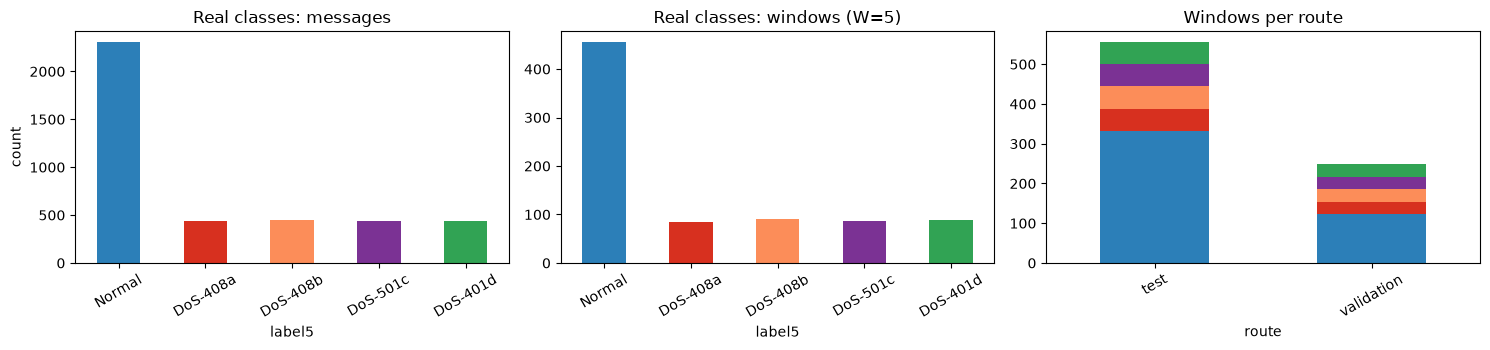

In [8]:
COL5 = {"Normal": "#2c7fb8", "DoS-408a": "#d7301f", "DoS-408b": "#fc8d59", "DoS-501c": "#7b3294", "DoS-401d": "#31a354"}
ORDER5 = list(COL5)

print("=== message level (raw telemetry) ===")
print("shape:", msg.shape)
print("columns:", list(msg.columns))
print("original file-name labels:", sorted(msg.kind.unique()), "(WA = without attack, A1 = DoS) | silenced anchor:", sorted(msg.victim.unique()))
print(msg.groupby(["kind", "victim", "route"]).size().rename("messages").to_string())
print("\n=== window level (what the models see) ===")
print("shape:", F.shape, "| feature names:", FEATS)
print("5-class counts:", F.label5.value_counts().reindex(ORDER5).to_dict())
print("binary counts :", {"Normal(0)": int((F.y == 0).sum()), "DoS(1)": int((F.y == 1).sum())})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
msg.label5.value_counts().reindex(ORDER5).plot.bar(ax=ax[0], color=[COL5[c] for c in ORDER5]); ax[0].set_title("Real classes: messages"); ax[0].set_ylabel("count")
F.label5.value_counts().reindex(ORDER5).plot.bar(ax=ax[1], color=[COL5[c] for c in ORDER5]); ax[1].set_title(f"Real classes: windows (W={WINDOW})")
pd.crosstab(F.route, F.label5)[ORDER5].plot.bar(ax=ax[2], stacked=True, color=[COL5[c] for c in ORDER5], legend=False); ax[2].set_title("Windows per route")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

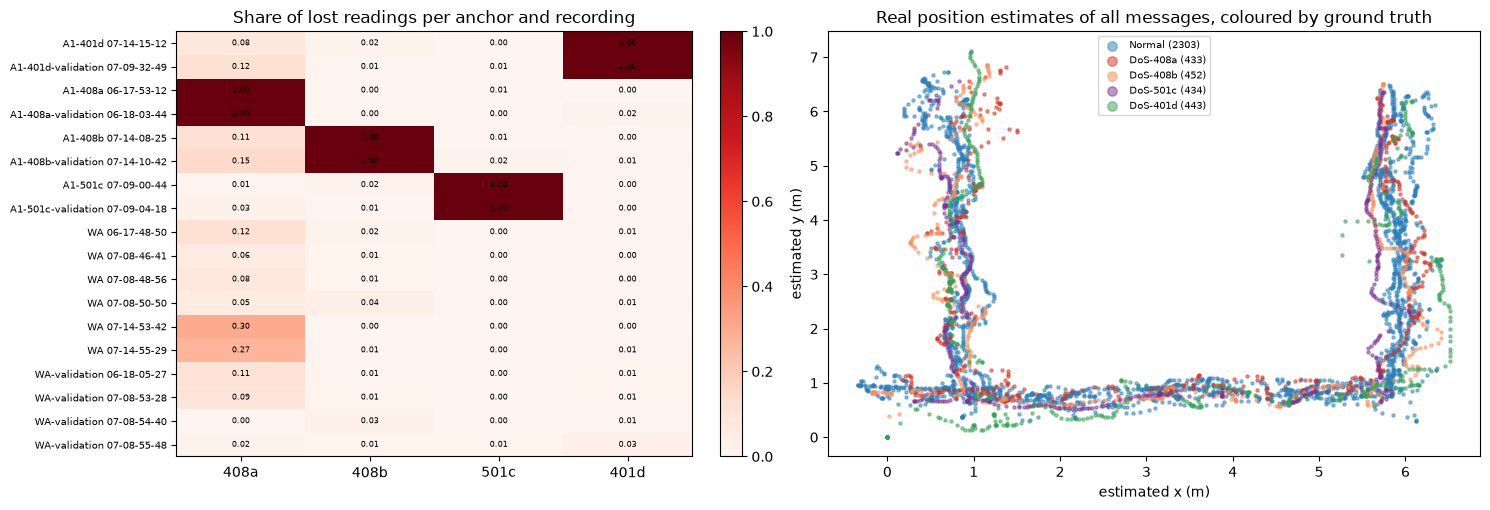

In [9]:
# share of lost anchor readings per run and anchor: the DoS signature (one anchor silent) versus the occasional natural drop-outs
loss = msg.groupby("run")[["d_" + a for a in ANCHORS]].apply(lambda g: g.isna().mean())
loss.columns = ANCHORS
order_runs = list(msg.drop_duplicates("run").sort_values(["kind", "victim", "route"]).run)
loss = loss.loc[order_runs]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
im = ax[0].imshow(loss.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(ANCHORS); ax[0].set_yticks(range(len(loss))); ax[0].set_yticklabels([r.replace("_2017-03-", " ") for r in loss.index], fontsize=7)
for i in range(loss.shape[0]):
    for j in range(4): ax[0].text(j, i, f"{loss.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
ax[0].set_title("Share of lost readings per anchor and recording"); plt.colorbar(im, ax=ax[0], fraction=0.04)
for c in ORDER5:
    s = msg[msg.label5 == c]
    ax[1].scatter(s.px, s.py, s=5, alpha=0.5, color=COL5[c], label=f"{c} ({len(s)})")
ax[1].set_xlabel("estimated x (m)"); ax[1].set_ylabel("estimated y (m)"); ax[1].set_title("Real position estimates of all messages, coloured by ground truth")
ax[1].legend(markerscale=3, fontsize=7); plt.tight_layout(); plt.show()

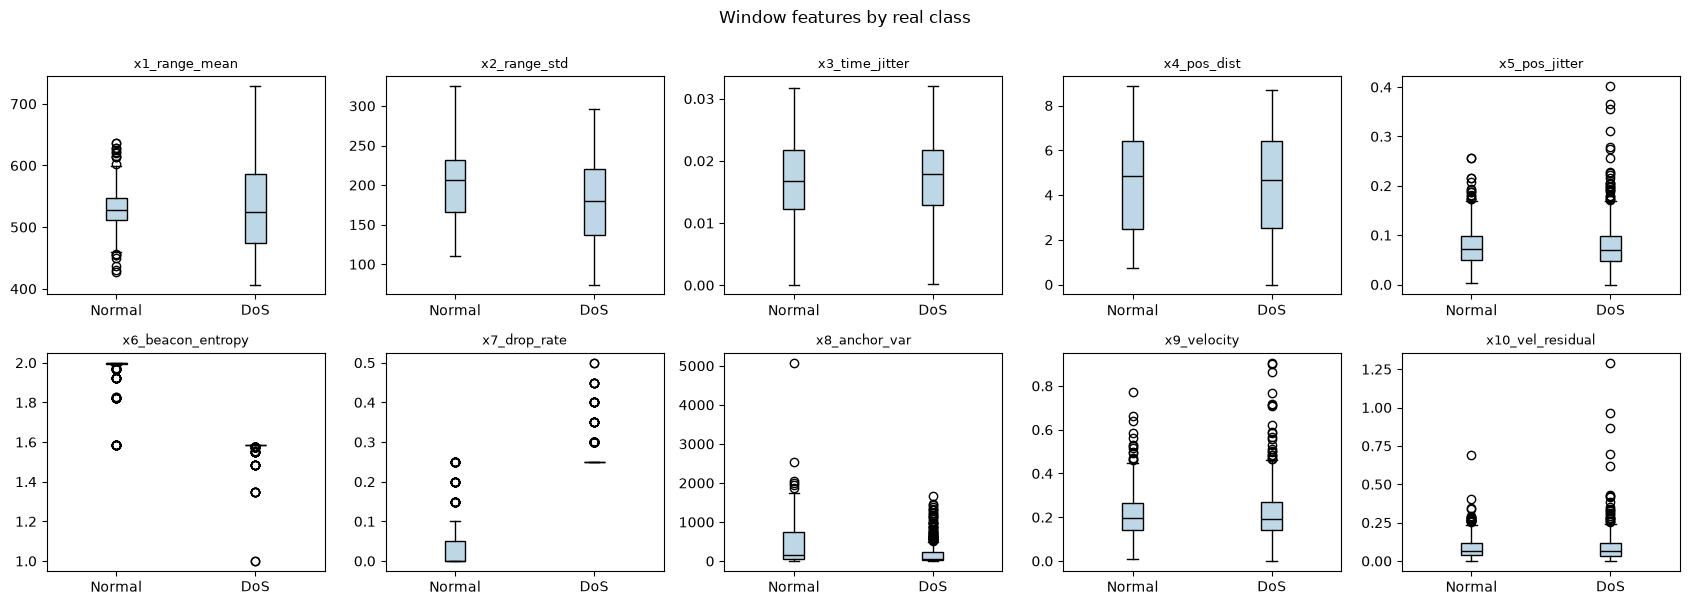

In [10]:
# the ten window features by real class (box plots, binary label)
fig, axs = plt.subplots(2, 5, figsize=(17, 6))
for a, f in zip(axs.ravel(), FEATS):
    a.boxplot([F.loc[F.y == 0, f], F.loc[F.y == 1, f]], patch_artist=True,
              boxprops=dict(facecolor="#bdd7e7"), medianprops=dict(color="k"))
    a.set_xticks([1, 2]); a.set_xticklabels(["Normal", "DoS"])
    a.set_title(f, fontsize=9)
plt.suptitle("Window features by real class", y=1.0); plt.tight_layout(); plt.show()

explained variance of the two PCA axes: [0.261 0.179]


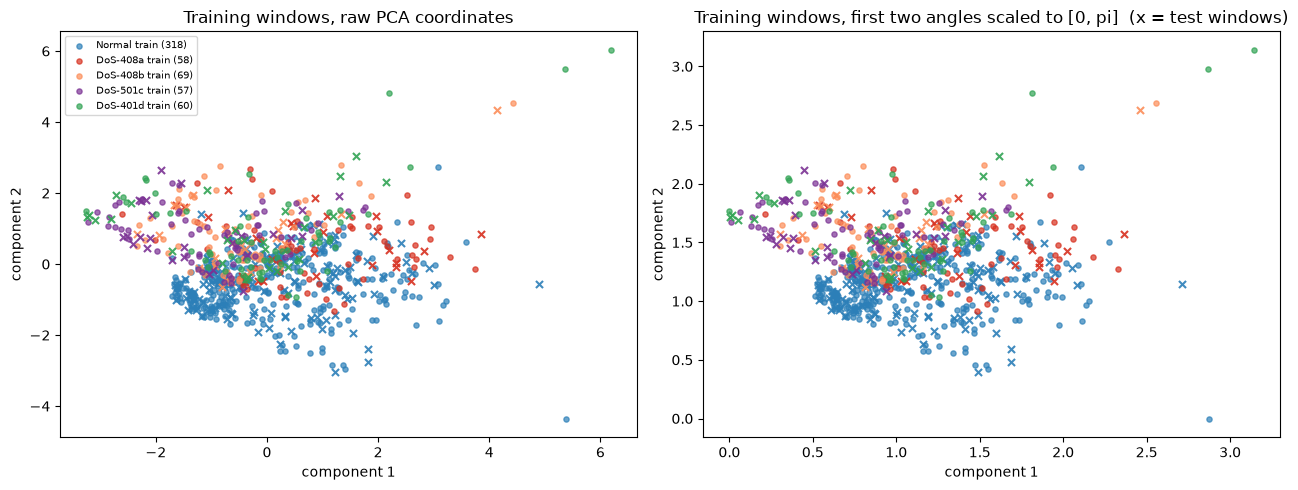

In [11]:
# 2-D scatter of the real training windows (paper privacy condition), coloured by ground-truth label.
# (1) raw PCA coordinates (PCA fitted on the training split), (2) the same coordinates scaled to [0, pi] (angle range of the circuit).
tr_df, te_df = make_split(F, "random", SEED)
Xa, Xb, ya, yb, _ = transform(tr_df, te_df, "paper")
pca = PCA(n_components=2, random_state=SEED).fit(Xa)
Za, Zb = pca.transform(Xa), pca.transform(Xb)
mm = MinMaxScaler((0, np.pi)).fit(Za)
Ta, Tb = mm.transform(Za), np.clip(mm.transform(Zb), 0, np.pi)
print("explained variance of the two PCA axes:", pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for (P, Q, ttl, a) in [(Za, Zb, "Training windows, raw PCA coordinates", ax[0]), (Ta, Tb, "Training windows, first two angles scaled to [0, pi]", ax[1])]:
    for c in ORDER5:
        m_tr = (tr_df.label5.values == c); m_te = (te_df.label5.values == c)
        a.scatter(P[m_tr, 0], P[m_tr, 1], s=14, alpha=0.7, color=COL5[c], label=f"{c} train ({m_tr.sum()})")
        a.scatter(Q[m_te, 0], Q[m_te, 1], s=26, marker="x", color=COL5[c], alpha=0.9)
    a.set_title(ttl); a.set_xlabel("component 1"); a.set_ylabel("component 2")
ax[0].legend(fontsize=7); ax[1].set_title(ax[1].get_title() + "  (x = test windows)")
plt.tight_layout(); plt.show()

## 4. The models

All networks are small PyTorch modules.

- **NN**: one hidden layer of 16 ReLU units.
- **DNN-Shallow**: one hidden layer of 8 Swish units with dropout (the paper's "single hidden layer and limited neurons").
- **DNN**: the paper's CNN-LSTM. The 7 (or 9, or 10) standardised features are read as a short sequence with one step per
  feature; a 1-D convolution (16 channels) feeds an LSTM (32 units), followed by dropout and a two-layer dense head. Swish
  activation and dropout 0.4 are the optimum the paper reports in Fig. 12.
- **Hybrid DQNN + NN / DQNN + DNN**: two branches run **in parallel** on the same input.
  *Quantum branch*: a linear layer compresses the features to `n_q` numbers, `tanh x pi` turns them into rotation angles
  (the paper's "DNN-based dimensionality reduction in DQNN"), a variational circuit on `n_q` qubits processes them and
  returns the Pauli-Z expectation value of every qubit, and a linear head turns those into two class logits.
  *Classical branch*: the NN or DNN above.
  *Fusion*: a small trainable gate looks at the quantum expectation values and the classical logits and outputs a weight
  `g` in (0, 1); the final logits are `g * quantum + (1 - g) * classical`. This is the "trainable, confidence-weighted
  fusion" of the paper (the exact form is our choice).
- **Baselines on identical inputs**: Random Forest (200 trees) and an RBF-SVM (`C = 1`, scikit-learn defaults otherwise).

The circuit (angle encoding with RX, two layers of trainable RY and RX rotations, a CNOT ring, Pauli-Z read-out) follows
the paper's Fig. 1 label "Encode - RX/RY - CNOT - Measure"; the paper gives no further details.

In [12]:
class Swish(nn.Module):
    def forward(self, x): return x * torch.sigmoid(x)

def act_layer(name): return {"swish": Swish, "relu": nn.ReLU, "tanh": nn.Tanh}[name]()

class NN(nn.Module):
    def __init__(self, d, hidden=16, drop=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden, 2))
    def forward(self, x): return self.net(x)

class DNNShallow(nn.Module):
    def __init__(self, d, hidden=8, drop=0.4, act="swish"):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, hidden), act_layer(act), nn.Dropout(drop), nn.Linear(hidden, 2))
    def forward(self, x): return self.net(x)

class DNN(nn.Module):
    """CNN-LSTM branch: the feature vector is read as a sequence with one step per feature."""
    def __init__(self, d, drop=0.4, act="swish", ch=16, hid=32):
        super().__init__()
        self.conv = nn.Conv1d(1, ch, 3, padding=1); self.act = act_layer(act)
        self.lstm = nn.LSTM(ch, hid, batch_first=True); self.drop = nn.Dropout(drop)
        self.head = nn.Sequential(nn.Linear(hid, 16), act_layer(act), nn.Dropout(drop), nn.Linear(16, 2))
    def forward(self, x):
        h = self.act(self.conv(x.unsqueeze(1))).transpose(1, 2)        # batch x features x channels
        _, (hn, _) = self.lstm(h)
        return self.head(self.drop(hn[-1]))

def make_classical(kind, d, drop=DROPOUT_PAPER, act=ACT_PAPER):
    return {"NN": lambda: NN(d), "DNN-Shallow": lambda: DNNShallow(d, drop=drop, act=act),
            "DNN": lambda: DNN(d, drop=drop, act=act)}[kind]()

N_LAYERS = 2   # CHOICE: variational layers of the circuit

def make_qnode(n_q, n_layers=N_LAYERS):
    dev = qml.device("default.qubit", wires=n_q)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        for i in range(n_q):
            qml.RX(inputs[..., i], wires=i)                  # angle encoding of the (reduced) features
        for l in range(n_layers):
            for i in range(n_q):
                qml.RY(weights[l, i, 0], wires=i)            # trainable rotations
                qml.RX(weights[l, i, 1], wires=i)
            if n_q == 2:
                qml.CNOT(wires=[0, 1])
            else:
                for i in range(n_q):
                    qml.CNOT(wires=[i, (i + 1) % n_q])       # ring entanglement
        return [qml.expval(qml.PauliZ(i)) for i in range(n_q)]
    return circuit, {"weights": (n_layers, n_q, 2)}

class Hybrid(nn.Module):
    """DQNN branch (reduction -> variational circuit -> head) in parallel with a classical branch + trainable fusion gate."""
    def __init__(self, d, n_q, classical="DNN", drop=DROPOUT_PAPER, act=ACT_PAPER):
        super().__init__()
        self.n_q = n_q
        self.reduce = nn.Linear(d, n_q)
        circuit, shapes = make_qnode(n_q)
        self.qlayer = qml.qnn.TorchLayer(circuit, shapes, init_method=lambda t: nn.init.uniform_(t, 0, 2 * np.pi))
        self.qhead = nn.Linear(n_q, 2)
        self.classical = make_classical(classical, d, drop, act)
        self.gate = nn.Linear(n_q + 2, 1)
    def angles(self, x): return torch.tanh(self.reduce(x)) * np.pi
    def branches(self, x):
        q = self.qlayer(self.angles(x)); c = self.classical(x)
        g = torch.sigmoid(self.gate(torch.cat([q, c], dim=1)))
        return q, c, g
    def forward(self, x):
        q, c, g = self.branches(x)
        return g * self.qhead(q) + (1 - g) * c

def train_torch(model, Xtr, ytr, Xte, epochs, seed):
    opt = torch.optim.Adam(model.parameters(), lr=LR); lossf = nn.CrossEntropyLoss()
    X = torch.tensor(Xtr, dtype=torch.float32); Y = torch.tensor(ytr, dtype=torch.long)
    gen = torch.Generator().manual_seed(seed); t0 = time.time(); hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X), generator=gen); tot = 0.0
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]; opt.zero_grad()
            loss = lossf(model(X[idx]), Y[idx]); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        hist.append(tot / len(X))
    train_time = time.time() - t0
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(Xte, dtype=torch.float32))
    return logits.argmax(1).numpy(), train_time, hist

def metrics(y, p):
    P, R, F1, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    return dict(acc=accuracy_score(y, p), prec=P, rec=R, f1=F1, macro_f1=f1_score(y, p, average="macro"),
                attack_f1=f1_score(y, p, pos_label=1, zero_division=0))
print("model classes defined")

model classes defined


## Quantum Circuit Architecture

The circuits below are the **exact `QNode` objects** that the hybrid models execute: each is taken from the model's own
`TorchLayer` (`model.qlayer.qnode`), not redrawn by hand. One drawing per distinct architecture (2, 4 and 6 qubits).
Reading a drawing from left to right: `RX(x_i)` encodes the i-th reduced feature as a rotation angle; each of the two
variational layers applies a trainable `RY` and `RX` per qubit and then entangles with CNOT gates (a single CNOT for two
qubits, a ring for four and six); the last column measures the Pauli-Z expectation value of every qubit.
Assumptions where the paper is silent: 2 variational layers, RX encoding, RY+RX rotations, ring entanglement, no data
re-uploading, initial weights uniform in [0, 2 pi]. The linear reduction and the heads are classical layers around the circuit.

Matplotlib is building the font cache; this may take a moment.


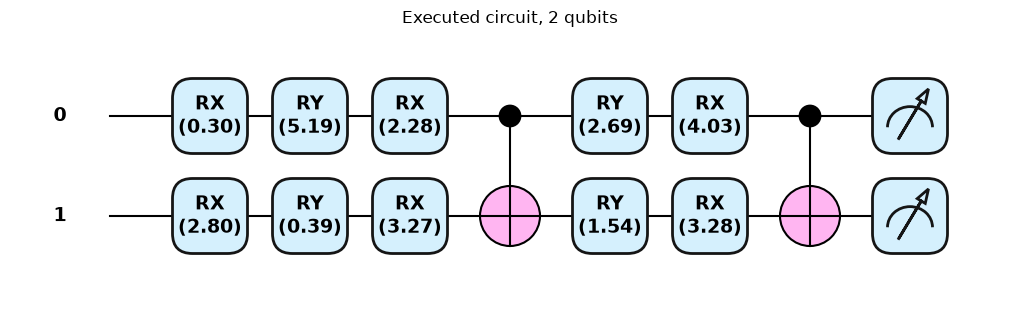

Matplotlib is building the font cache; this may take a moment.


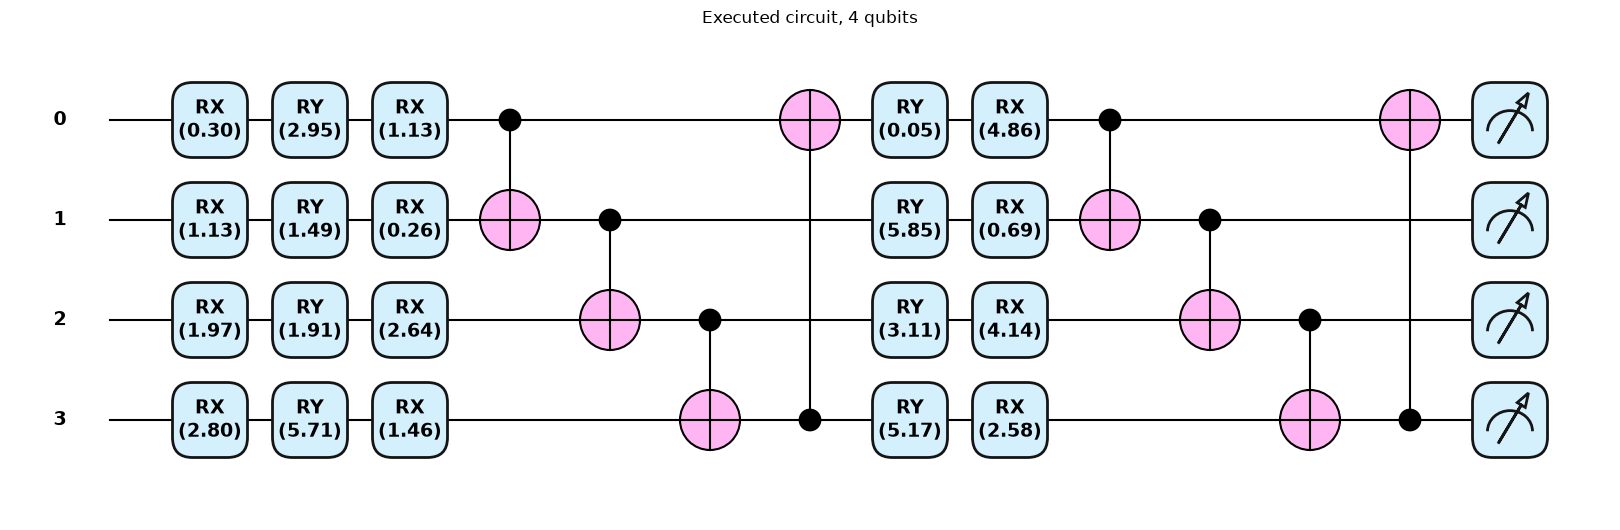

Matplotlib is building the font cache; this may take a moment.


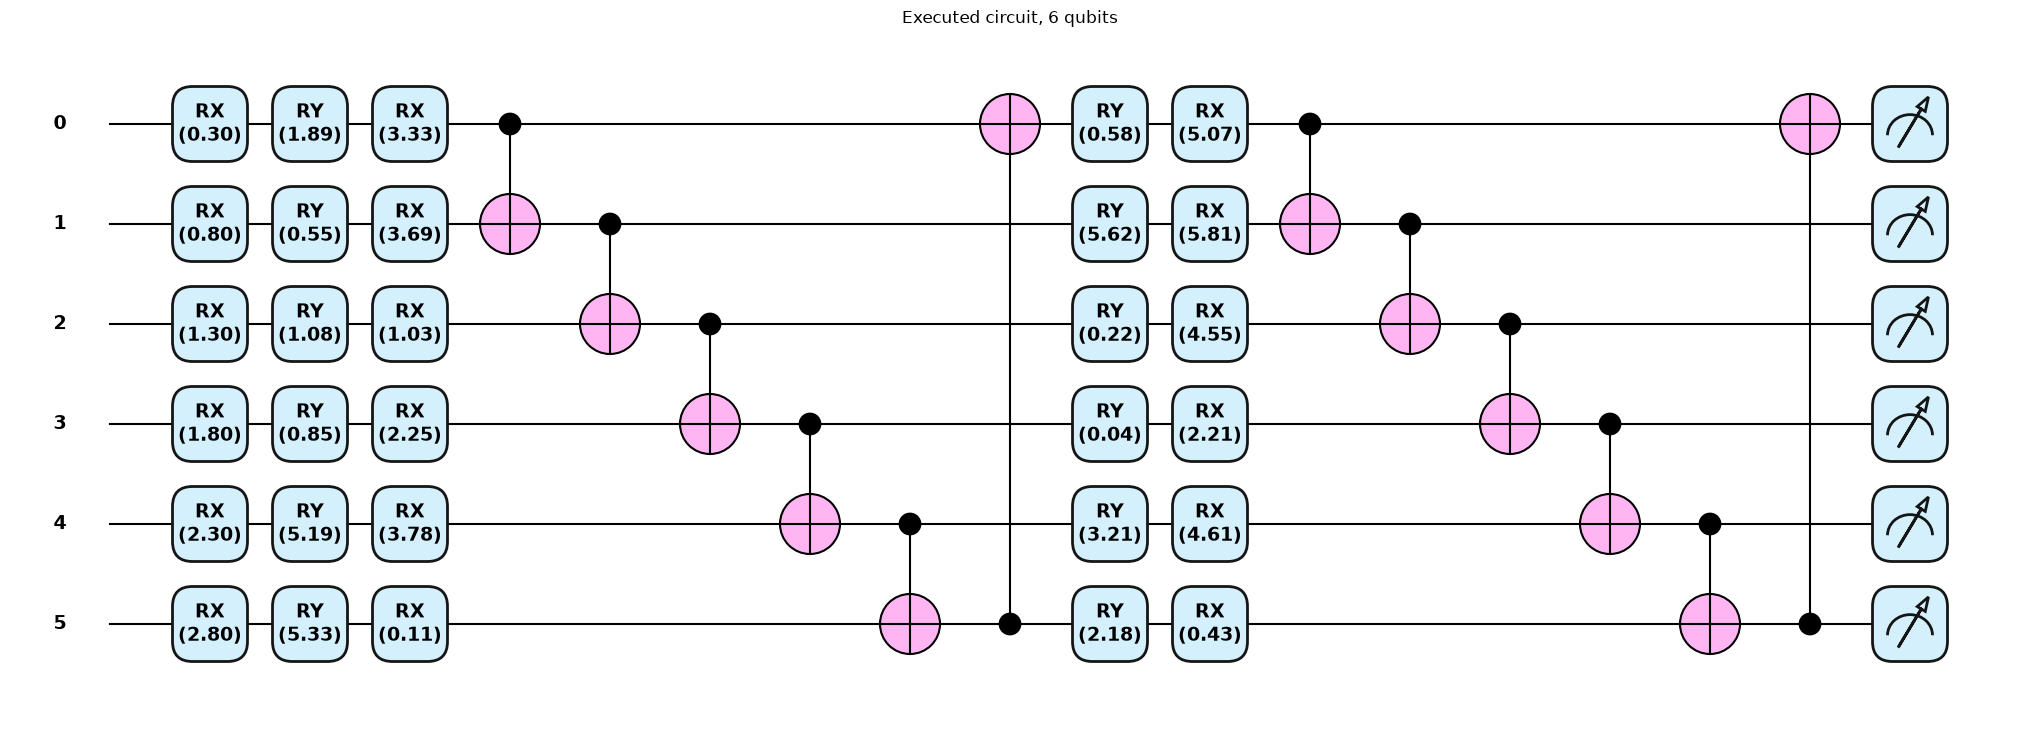

,qubits,depth,gates,circuit_params,hybrid_total_params,measured
0,2,7,12,8,7061,<Z> on 2 qubits
1,4,13,28,16,7091,<Z> on 4 qubits
2,6,17,42,24,7121,<Z> on 6 qubits


In [13]:
CIRCUIT_INFO = []
for n_q in QUBITS:
    torch.manual_seed(SEED)
    hm = Hybrid(7, n_q, "DNN")
    qn = hm.qlayer.qnode                                         # the object that is executed during training and inference
    x_demo = torch.linspace(0.3, 2.8, n_q); w_demo = torch.rand(N_LAYERS, n_q, 2) * 2 * np.pi
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(x_demo, w_demo)
    fig.suptitle(f"Executed circuit, {n_q} qubits", y=1.02); plt.show()
    specs = qml.specs(qn, level="device")(x_demo, w_demo)
    res = specs["resources"] if isinstance(specs, dict) else specs.resources
    depth = res.depth; n_gates = res.num_gates
    n_circ_params = sum(p.numel() for p in hm.qlayer.parameters())
    n_total = sum(p.numel() for p in hm.parameters())
    # equivalence check: batched execution of the same QNode equals sample-by-sample execution
    xb = torch.rand(5, n_q) * np.pi
    assert torch.allclose(hm.qlayer(xb), torch.stack([torch.stack(qn(xb[i], hm.qlayer.weights)) for i in range(5)]).float(), atol=1e-5)
    CIRCUIT_INFO.append(dict(qubits=n_q, depth=depth, gates=n_gates, circuit_params=n_circ_params,
                             hybrid_total_params=n_total, measured=f"<Z> on {n_q} qubits"))
pd.DataFrame(CIRCUIT_INFO)

## 5. Train and evaluate every model (Table II)

`run()` trains one model on one split and returns the metrics. It is called for every model, for `N_REPS` repetitions
(each repetition = new random split and new initialisation), in the **paper** privacy condition. Table II of the paper
lists accuracy, precision, recall, F1 and training time; precision, recall and F1 are weighted averages over the two
classes (the paper's recall equals its accuracy, which only the weighted average does). We also report the Macro-F1 and the
Attack-F1 (DoS = positive class) the paper uses in Figs. 11-15.

In [14]:
RESULTS, KEEP = [], {}          # RESULTS: one dict per trained model; KEEP: models / predictions of repetition 0 for the figures

def run(model_name, cond="paper", protocol="random", rep=0, epochs=None, drop=DROPOUT_PAPER, act=ACT_PAPER, nn_drop=None, keep=False, record=True):
    seed = SEED + rep
    tr, te = make_split(F, protocol, seed)
    Xa, Xb, ya, yb, _ = transform(tr, te, cond)
    d = Xa.shape[1]; torch.manual_seed(seed); t0 = time.time()
    if model_name == "RF":
        m = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1).fit(Xa, ya); pred = m.predict(Xb); tt = time.time() - t0
    elif model_name == "SVC":
        m = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed).fit(Xa, ya); pred = m.predict(Xb); tt = time.time() - t0
    elif model_name in ("NN", "DNN-Shallow", "DNN"):
        m = NN(d, drop=nn_drop) if (model_name == "NN" and nn_drop is not None) else make_classical(model_name, d, drop, act)
        pred, tt, hist = train_torch(m, Xa, ya, Xb, epochs or EPOCHS_CLASSICAL, seed)
    else:                                                       # "Hybrid DQNN+NN q4"
        fam, q = model_name.split(" q"); m = Hybrid(d, int(q), fam.split("+")[1], drop, act)
        pred, tt, hist = train_torch(m, Xa, ya, Xb, epochs or EPOCHS_HYBRID, seed)
    res = dict(model=model_name, cond=cond, protocol=protocol, rep=rep, time=tt, n_test=len(yb), **metrics(yb, pred))
    if record: RESULTS.append(res)
    if keep: KEEP[(model_name, cond, protocol, rep)] = dict(model=m, Xa=Xa, Xb=Xb, ya=ya, yb=yb, pred=pred, tr=tr, te=te)
    return res

MODELS_CLASSICAL = ["RF", "SVC", "NN", "DNN-Shallow", "DNN"]
MODELS_HYBRID = [f"Hybrid DQNN+{c} q{q}" for c in ("NN", "DNN") for q in QUBITS]
t_all = time.time()
for protocol in ("random", "route"):
    for rep in range(N_REPS if protocol == "random" else ROUTE_REPS):
        for mname in MODELS_CLASSICAL + MODELS_HYBRID:
            r = run(mname, "paper", protocol, rep, keep=(rep == 0 and protocol == "random"))
            print(f"{protocol:6s} rep{rep} {mname:22s} acc={r['acc']:.3f} attackF1={r['attack_f1']:.3f} time={r['time']:.1f}s")
print(f"total {time.time()-t_all:.0f} s")

random rep0 RF                     acc=0.967 attackF1=0.962 time=3.4s


random rep0 SVC                    acc=0.942 attackF1=0.936 time=0.1s


random rep0 NN                     acc=0.959 attackF1=0.953 time=4.3s


random rep0 DNN-Shallow            acc=0.967 attackF1=0.963 time=5.0s


random rep0 DNN                    acc=0.963 attackF1=0.958 time=19.1s


...

route  rep2 Hybrid DQNN+NN q4      acc=0.972 attackF1=0.971 time=36.6s


route  rep2 Hybrid DQNN+NN q6      acc=0.976 attackF1=0.976 time=67.0s


route  rep2 Hybrid DQNN+DNN q2     acc=0.964 attackF1=0.963 time=14.8s


route  rep2 Hybrid DQNN+DNN q4     acc=0.960 attackF1=0.959 time=33.5s


route  rep2 Hybrid DQNN+DNN q6     acc=0.964 attackF1=0.963 time=57.5s
total 2729 s


In [15]:
R = pd.DataFrame(RESULTS)
def table(protocol, cond="paper"):
    g = R[(R.protocol == protocol) & (R.cond == cond)].groupby("model", sort=False)
    out = pd.DataFrame({"reps": g.size(), "acc": g.acc.mean(), "acc_std": g.acc.std().fillna(0), "prec": g.prec.mean(), "rec": g.rec.mean(),
                        "f1": g.f1.mean(), "attack_f1": g.attack_f1.mean(), "train_s": g.time.mean()})
    return out.round(3)
print("Random 70/30 window split, paper privacy condition (mean over repetitions):")
display_df = table("random"); display(display_df)
print("Route protocol (train on test route, evaluate on validation route):")
display(table("route"))

Random 70/30 window split, paper privacy condition (mean over repetitions):


,reps,acc,acc_std,prec,rec,f1,attack_f1,train_s
model,,,,,,,,
RF,5,0.966,0.005,0.967,0.966,0.966,0.962,3.010
SVC,5,0.955,0.014,0.956,0.955,0.955,0.949,0.056
NN,5,0.961,0.009,0.962,0.961,0.961,0.956,3.748
DNN-Shallow,5,0.970,0.009,0.971,0.970,0.970,0.967,3.588
DNN,5,0.952,0.016,0.952,0.952,0.952,0.945,14.472
Hybrid DQNN+NN q2,5,0.969,0.009,0.969,0.969,0.969,0.964,24.056
Hybrid DQNN+NN q4,5,0.963,0.018,0.963,0.963,0.963,0.958,48.959
Hybrid DQNN+NN q6,5,0.963,0.005,0.964,0.963,0.963,0.958,110.056
Hybrid DQNN+DNN q2,5,0.960,0.011,0.961,0.960,0.960,0.954,27.072


Route protocol (train on test route, evaluate on validation route):


,reps,acc,acc_std,prec,rec,f1,attack_f1,train_s
model,,,,,,,,
RF,3,0.972,0.000,0.973,0.972,0.972,0.971,1.457
SVC,3,0.964,0.000,0.965,0.964,0.964,0.963,0.033
NN,3,0.985,0.002,0.986,0.985,0.985,0.985,2.183
DNN-Shallow,3,0.969,0.012,0.971,0.969,0.969,0.969,2.317
DNN,3,0.957,0.018,0.959,0.957,0.957,0.956,8.267
Hybrid DQNN+NN q2,3,0.984,0.011,0.985,0.984,0.984,0.984,15.590
Hybrid DQNN+NN q4,3,0.980,0.008,0.981,0.980,0.980,0.980,34.846
Hybrid DQNN+NN q6,3,0.975,0.002,0.976,0.975,0.975,0.974,70.716
Hybrid DQNN+DNN q2,3,0.969,0.006,0.971,0.969,0.969,0.969,22.100


### Table II side by side with the paper

In [16]:
PAPER_T2 = {   # model: (qubits label, acc, train time s, precision, recall, F1)  -- Table II of the paper
    "DNN": (0.895, 40.596, 0.902, 0.896, 0.895), "NN": (0.795, 26.899, 0.832, 0.796, 0.790),
    "DNN-Shallow": (0.857, 26.462, 0.873, 0.858, 0.856),
    "Hybrid DQNN+NN q2": (0.908, 2217.539, 0.913, 0.908, 0.908), "Hybrid DQNN+NN q4": (0.910, 3104.622, 0.913, 0.910, 0.909),
    "Hybrid DQNN+NN q6": (0.900, 3529.502, 0.906, 0.900, 0.900), "Hybrid DQNN+DNN q2": (0.532, 2271.870, 0.535, 0.531, 0.514),
    "Hybrid DQNN+DNN q4": (0.952, 3103.029, 0.952, 0.952, 0.952), "Hybrid DQNN+DNN q6": (0.929, 3478.583, 0.930, 0.929, 0.929)}
rows = []
tab_r = table("random"); tab_o = table("route")
for m, (acc, tt, p, r_, f1) in PAPER_T2.items():
    a = R[(R.model == m) & (R.protocol == "random") & (R.cond == "paper")].acc
    rows.append(dict(model=m, paper_acc=acc, paper_F1=f1, paper_time_s=tt,
                     nb_acc_random=f"{a.mean():.3f} +- {a.std() if len(a) > 1 else 0:.3f}", nb_F1_random=tab_r.loc[m, "f1"],
                     nb_acc_route=tab_o.loc[m, "acc"], nb_time_s=tab_r.loc[m, "train_s"]))
T2 = pd.DataFrame(rows).set_index("model"); T2

,paper_acc,paper_F1,paper_time_s,nb_acc_random,nb_F1_random,nb_acc_route,nb_time_s
model,,,,,,,
DNN,0.895,0.895,40.596,0.952 +- 0.016,0.952,0.957,14.472
NN,0.795,0.790,26.899,0.961 +- 0.009,0.961,0.985,3.748
DNN-Shallow,0.857,0.856,26.462,0.970 +- 0.009,0.970,0.969,3.588
Hybrid DQNN+NN q2,0.908,0.908,2217.539,0.969 +- 0.009,0.969,0.984,24.056
Hybrid DQNN+NN q4,0.910,0.909,3104.622,0.963 +- 0.018,0.963,0.980,48.959
Hybrid DQNN+NN q6,0.900,0.900,3529.502,0.963 +- 0.005,0.963,0.975,110.056
Hybrid DQNN+DNN q2,0.532,0.514,2271.870,0.960 +- 0.011,0.960,0.969,27.072
Hybrid DQNN+DNN q4,0.952,0.952,3103.029,0.964 +- 0.011,0.964,0.972,51.845
Hybrid DQNN+DNN q6,0.929,0.929,3478.583,0.961 +- 0.006,0.961,0.964,92.820


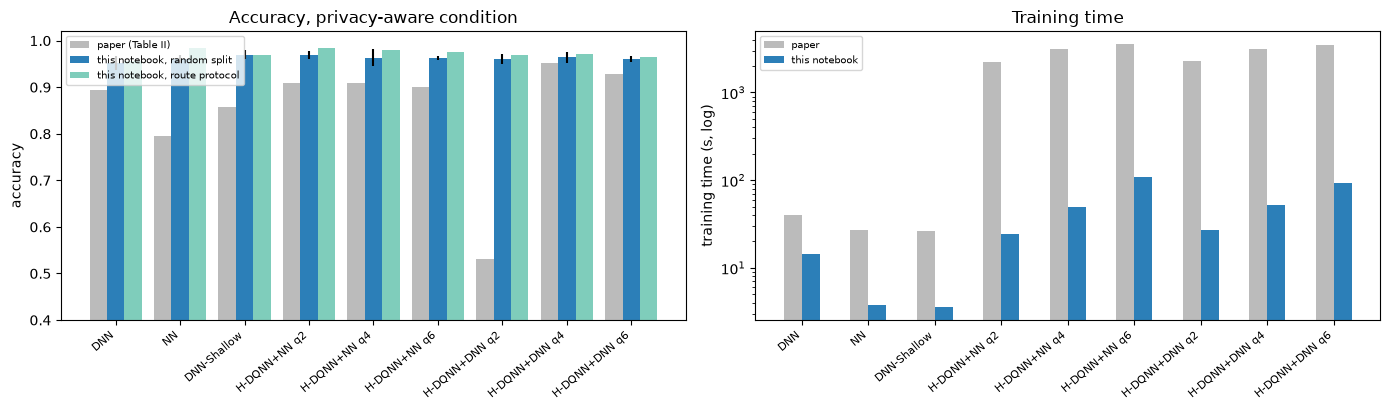

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
names = list(PAPER_T2); xs = np.arange(len(names)); w = 0.27
ax[0].bar(xs - w, [PAPER_T2[m][0] for m in names], w, label="paper (Table II)", color="#bbbbbb")
ax[0].bar(xs, [tab_r.loc[m, "acc"] for m in names], w, yerr=[tab_r.loc[m, "acc_std"] for m in names], label="this notebook, random split", color="#2c7fb8")
ax[0].bar(xs + w, [tab_o.loc[m, "acc"] for m in names], w, label="this notebook, route protocol", color="#7fcdbb")
ax[0].set_xticks(xs); ax[0].set_xticklabels([n.replace("Hybrid ", "H-") for n in names], rotation=40, ha="right", fontsize=8)
ax[0].set_ylim(0.4, 1.02); ax[0].set_ylabel("accuracy"); ax[0].legend(fontsize=7); ax[0].set_title("Accuracy, privacy-aware condition")
ax[1].bar(xs - w / 2, [PAPER_T2[m][1] for m in names], w, color="#bbbbbb", label="paper"); ax[1].bar(xs + w / 2, [tab_r.loc[m, "train_s"] for m in names], w, color="#2c7fb8", label="this notebook")
ax[1].set_yscale("log"); ax[1].set_xticks(xs); ax[1].set_xticklabels([n.replace("Hybrid ", "H-") for n in names], rotation=40, ha="right", fontsize=8)
ax[1].set_ylabel("training time (s, log)"); ax[1].legend(fontsize=7); ax[1].set_title("Training time")
plt.tight_layout(); plt.show()

### The trained 4-qubit circuit: angles actually fed to the quantum branch

The scatter in the exploration section used PCA coordinates. The angles that the circuit really receives are produced by
the trained linear reduction layer of the hybrid model. Here are the first two of them for the training windows, coloured
by ground truth (4 qubits, repetition 0).

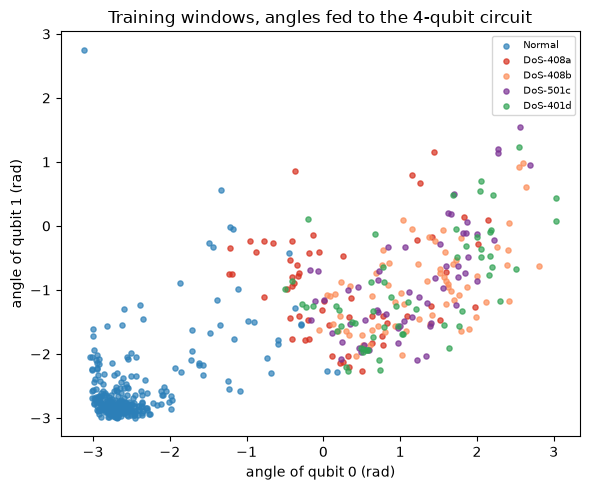

In [18]:
hk = KEEP[("Hybrid DQNN+DNN q4", "paper", "random", 0)]
hm = hk["model"]; hm.eval()
with torch.no_grad():
    ang_tr = hm.angles(torch.tensor(hk["Xa"], dtype=torch.float32)).numpy()
fig, ax = plt.subplots(figsize=(6, 5))
for c in ORDER5:
    mk = hk["tr"].label5.values == c
    ax.scatter(ang_tr[mk, 0], ang_tr[mk, 1], s=14, alpha=0.7, color=COL5[c], label=c)
ax.set_xlabel("angle of qubit 0 (rad)"); ax.set_ylabel("angle of qubit 1 (rad)"); ax.set_title("Training windows, angles fed to the 4-qubit circuit"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. Confusion matrices (paper Figs. 9 and 10)

The paper shows the confusion matrix of the DNN (Fig. 9) and of the 4-qubit hybrid DQNN+DNN (Fig. 10) and argues that the hybrid
reduces the false negatives, i.e. missed attacks, which is the dangerous error for a robot. Same models, same test windows, first repetition.

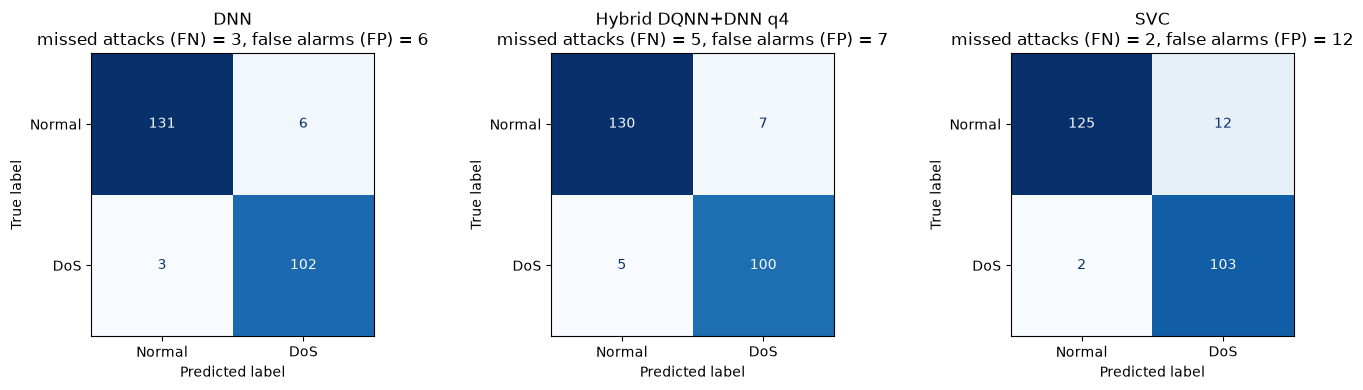

false negatives / false positives: {'DNN': (3, 6), 'Hybrid DQNN+DNN q4': (5, 7), 'SVC': (2, 12)}


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
FN = {}
for a, m in zip(ax, ["DNN", "Hybrid DQNN+DNN q4", "SVC"]):
    k = KEEP[(m, "paper", "random", 0)]
    cm = confusion_matrix(k["yb"], k["pred"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "DoS"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{m}\nmissed attacks (FN) = {cm[1, 0]}, false alarms (FP) = {cm[0, 1]}"); FN[m] = (int(cm[1, 0]), int(cm[0, 1]))
plt.tight_layout(); plt.show()
print("false negatives / false positives:", FN)

## 7. Dropout rate for the NN (paper Fig. 11)

The paper sweeps the dropout rate (0.3 to 0.8) and plots Macro-F1, Weighted-F1 and Attack-F1 of the NN; it finds that about
30 % is the best compromise. The NN here gets a dropout layer after its hidden layer. This sweep reports test-set scores
as a *description* (as the paper does); the models of Table II were **not** tuned with it (they use the paper's fixed
values), so it does not leak into the comparison above.

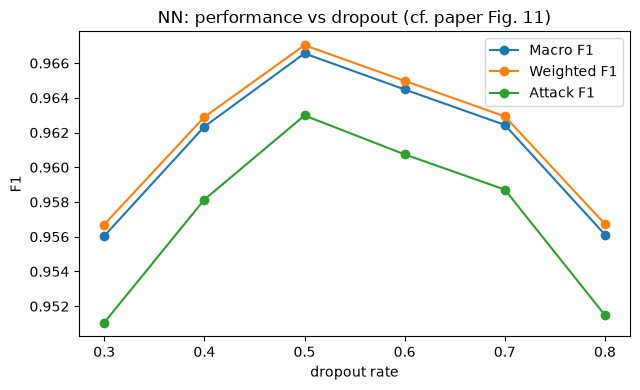

         macro_f1     f1  attack_f1
dropout                            
0.3         0.956  0.957      0.951
0.4         0.962  0.963      0.958
0.5         0.967  0.967      0.963
0.6         0.964  0.965      0.961
0.7         0.962  0.963      0.959
0.8         0.956  0.957      0.951 
best dropout by Attack F1: 0.5 | sweep time 27 s


In [20]:
SW = []
t0 = time.time()
for p in SWEEP_DROPOUTS:
    for rep in range(SWEEP_REPS):
        r = run("NN", "paper", "random", rep, epochs=SWEEP_EPOCHS, nn_drop=p, record=False)
        SW.append(dict(dropout=p, rep=rep, **{k: r[k] for k in ("macro_f1", "f1", "attack_f1")}))
SW = pd.DataFrame(SW); swm = SW.groupby("dropout")[["macro_f1", "f1", "attack_f1"]].mean()
fig, ax = plt.subplots(figsize=(6.5, 4))
for c, l in [("macro_f1", "Macro F1"), ("f1", "Weighted F1"), ("attack_f1", "Attack F1")]:
    ax.plot(swm.index, swm[c], "o-", label=l)
ax.set_xlabel("dropout rate"); ax.set_ylabel("F1"); ax.set_title("NN: performance vs dropout (cf. paper Fig. 11)"); ax.legend(); plt.tight_layout(); plt.show()
print(swm.round(3).to_string(), f"\nbest dropout by Attack F1: {swm.attack_f1.idxmax()} | sweep time {time.time()-t0:.0f} s")

## 8. Activation function and dropout for the DNN (paper Figs. 12 to 15)

For the CNN-LSTM DNN the paper compares Swish, ReLU and Tanh over the dropout rate (Fig. 12, Attack F1) and draws radar plots of
Macro-, Weighted- and Attack-F1 for each activation (Figs. 13 ReLU, 14 Swish, 15 Tanh). It reports that Swish with 40 % dropout
is best and Tanh is worst and unstable.

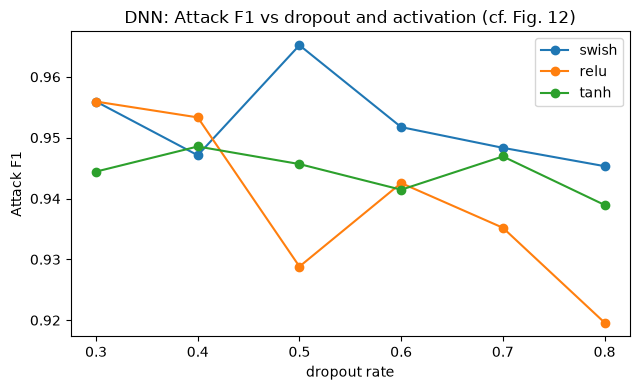

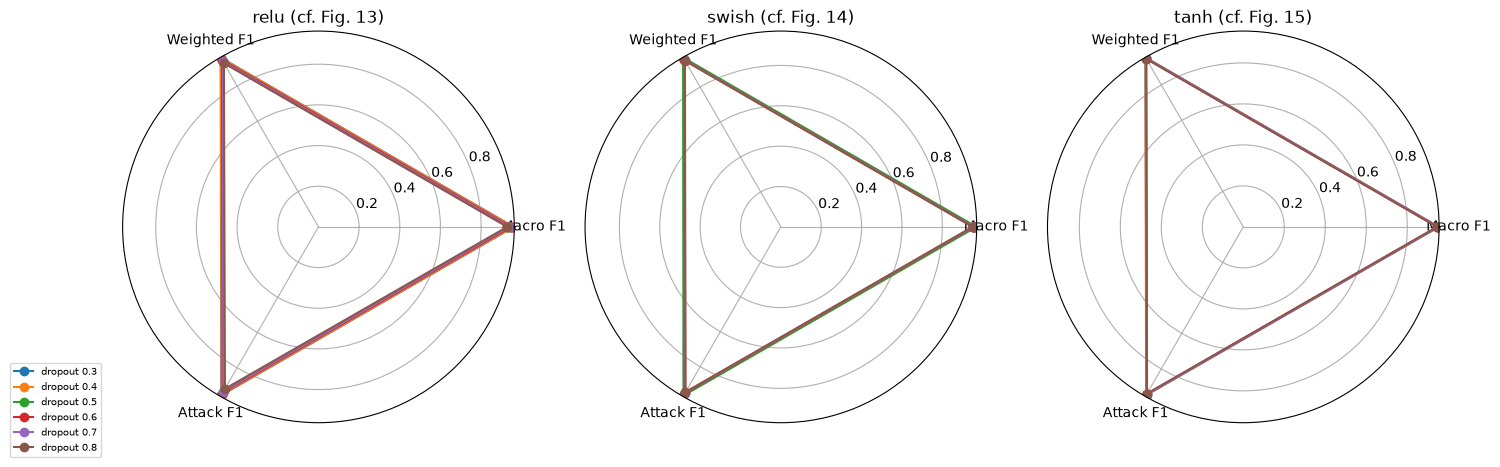

act       relu  swish   tanh
dropout                     
0.3      0.956  0.956  0.944
0.4      0.953  0.947  0.949
0.5      0.929  0.965  0.946
0.6      0.943  0.952  0.941
0.7      0.935  0.948  0.947
0.8      0.920  0.945  0.939

best (activation, dropout) by Attack F1: ('swish', 0.5) | activation with the lowest mean Attack F1: relu | sweep time 162 s


In [21]:
AC = []
t0 = time.time()
for act in ("swish", "relu", "tanh"):
    for p in SWEEP_DROPOUTS:
        for rep in range(SWEEP_REPS):
            r = run("DNN", "paper", "random", rep, epochs=SWEEP_EPOCHS, drop=p, act=act, record=False)
            AC.append(dict(act=act, dropout=p, rep=rep, **{k: r[k] for k in ("macro_f1", "f1", "attack_f1")}))
AC = pd.DataFrame(AC); acm = AC.groupby(["act", "dropout"])[["macro_f1", "f1", "attack_f1"]].mean()
fig, ax = plt.subplots(figsize=(6.5, 4))
for act in ("swish", "relu", "tanh"):
    s = acm.loc[act, "attack_f1"]; ax.plot(s.index, s.values, "o-", label=act)
ax.set_xlabel("dropout rate"); ax.set_ylabel("Attack F1"); ax.set_title("DNN: Attack F1 vs dropout and activation (cf. Fig. 12)"); ax.legend(); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), subplot_kw=dict(polar=True))
ang = np.linspace(0, 2 * np.pi, 4)
for a, act, fig_no in zip(axs, ("relu", "swish", "tanh"), (13, 14, 15)):
    for p in SWEEP_DROPOUTS:
        v = acm.loc[(act, p), ["macro_f1", "f1", "attack_f1"]].values.astype(float); v = np.r_[v, v[0]]
        a.plot(ang, v, "o-", label=f"dropout {p}")
    a.set_xticks(ang[:-1]); a.set_xticklabels(["Macro F1", "Weighted F1", "Attack F1"]); a.set_title(f"{act} (cf. Fig. {fig_no})")
axs[0].legend(loc="lower left", fontsize=7, bbox_to_anchor=(-0.3, -0.1))
plt.tight_layout(); plt.show()
best = tuple(acm.attack_f1.idxmax()); best = (best[0], float(best[1])); worst_act = acm.groupby("act").attack_f1.mean().idxmin()
print(acm.attack_f1.unstack(0).round(3).to_string())
print(f"\nbest (activation, dropout) by Attack F1: {best} | activation with the lowest mean Attack F1: {worst_act} | sweep time {time.time()-t0:.0f} s")

## 9. Privacy versus detection (the paper's Attack-F1(T_p(x)) versus Attack-F1(x))

Section III-B defines the trade-off the whole framework is about: how much Attack-F1 is lost when the privacy transform is
applied? Here the same models are trained on (i) all ten raw features, (ii) the paper condition (x4, x5, x6 deleted, x9 encoded)
and (iii) the fuller transform T_p, and their Attack-F1 on the test windows is compared. The 4-qubit hybrid is included.

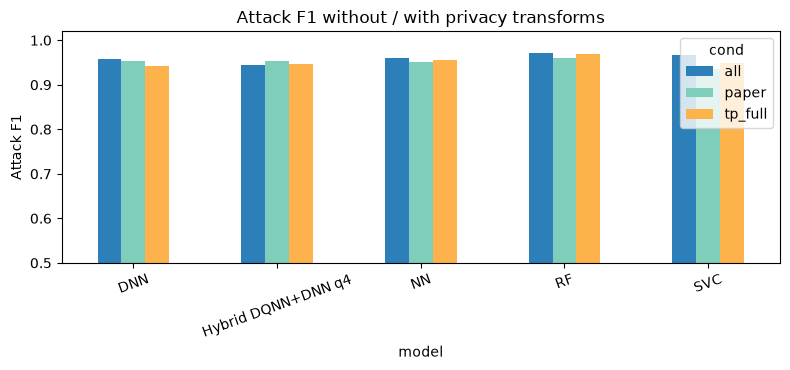

cond,all,paper,tp_full,loss_all_to_paper,loss_all_to_tp
model,,,,,
DNN,0.958,0.953,0.942,0.005,0.016
Hybrid DQNN+DNN q4,0.944,0.953,0.946,-0.009,-0.002
NN,0.960,0.951,0.955,0.009,0.004
RF,0.972,0.960,0.970,0.012,0.002
SVC,0.968,0.936,0.948,0.032,0.020


In [22]:
PR = []
for cond in ("all", "paper", "tp_full"):
    for mname in ["RF", "SVC", "NN", "DNN", "Hybrid DQNN+DNN q4"]:
        for rep in range(PR_REPS):
            r = run(mname, cond, "random", rep, record=False)
            PR.append(dict(cond=cond, model=mname, rep=rep, attack_f1=r["attack_f1"], acc=r["acc"]))
PR = pd.DataFrame(PR); prm = PR.groupby(["model", "cond"]).attack_f1.mean().unstack()[["all", "paper", "tp_full"]]
prm["loss_all_to_paper"] = prm["all"] - prm["paper"]; prm["loss_all_to_tp"] = prm["all"] - prm["tp_full"]
ax = prm[["all", "paper", "tp_full"]].plot.bar(figsize=(8, 3.8), color=["#2c7fb8", "#7fcdbb", "#feb24c"]); ax.set_ylim(0.5, 1.02); ax.set_ylabel("Attack F1")
ax.set_title("Attack F1 without / with privacy transforms"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()
prm.round(3)

## 10. t-SNE of the hybrid model's fused representation (paper Fig. 16)

The paper shows a t-SNE of its 4-qubit hybrid and says the attack and benign samples form distinct clusters. We embed the
fused representation `[quantum expectation values (4), classical logits (2), gate]` of the *test* windows with t-SNE and
report the silhouette score of the two real classes as a number (the paper's claim is visual only).

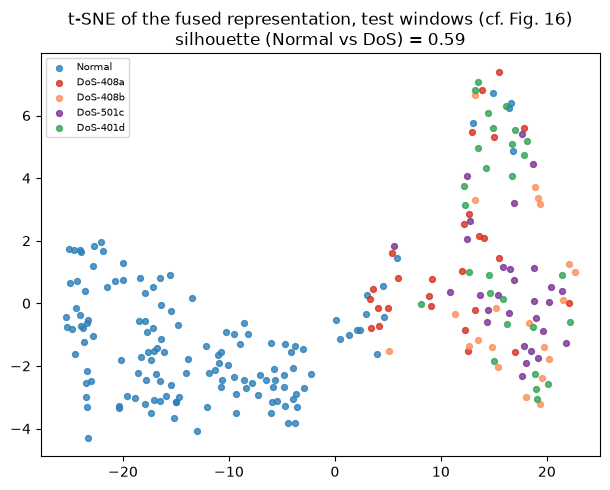

mean fusion gate g (weight of the quantum branch): all test windows = 0.933 | Normal = 0.993 | DoS = 0.854


In [23]:
hk = KEEP[("Hybrid DQNN+DNN q4", "paper", "random", 0)]; hm = hk["model"]; hm.eval()
with torch.no_grad():
    q, c, g = hm.branches(torch.tensor(hk["Xb"], dtype=torch.float32))
rep_vec = torch.cat([q, c, g], dim=1).numpy()
emb = TSNE(n_components=2, perplexity=min(30, len(rep_vec) // 4), random_state=SEED, init="pca").fit_transform(rep_vec)
sil = silhouette_score(rep_vec, hk["yb"])
fig, ax = plt.subplots(figsize=(6.2, 5))
for c_ in ORDER5:
    mk = hk["te"].label5.values == c_
    ax.scatter(emb[mk, 0], emb[mk, 1], s=18, color=COL5[c_], label=c_, alpha=0.8)
ax.set_title(f"t-SNE of the fused representation, test windows (cf. Fig. 16)\nsilhouette (Normal vs DoS) = {sil:.2f}"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("mean fusion gate g (weight of the quantum branch): all test windows =", round(float(g.mean()), 3),
      "| Normal =", round(float(g[torch.tensor(hk['yb']) == 0].mean()), 3), "| DoS =", round(float(g[torch.tensor(hk['yb']) == 1].mean()), 3))

## 11. Side-by-side with the paper: one verdict per claim

Rules (from the project): a number is **reproduced** if it is within 0.02 of the paper (accuracy, F1); otherwise it is
**exceeded** (notebook higher) or **not reached** (notebook lower) with the gap. Ranking claims are checked on the mean over
repetitions of the random-split protocol. Claims that need data or settings the paper does not give are marked
**cannot be checked**.

In [24]:
def v_num(paper, nb, tol=0.02):
    d = nb - paper
    return f"reproduced ({d:+.3f})" if abs(d) <= tol else (f"exceeded ({d:+.3f})" if d > 0 else f"not reached ({d:+.3f})")

claims = []
def add(claim, paper, nb, verdict): claims.append(dict(claim=claim, paper=paper, notebook=nb, verdict=verdict))

for m, (acc, tt, p_, r_, f1) in PAPER_T2.items():
    add(f"Table II accuracy, {m}", acc, round(float(tab_r.loc[m, "acc"]), 3), v_num(acc, tab_r.loc[m, "acc"]))
    add(f"Table II F1, {m}", f1, round(float(tab_r.loc[m, "f1"]), 3), v_num(f1, tab_r.loc[m, "f1"]))

acc = tab_r["acc"]
best_h = {fam: max(QUBITS, key=lambda q: acc[f"Hybrid DQNN+{fam} q{q}"]) for fam in ("NN", "DNN")}
best_hybrid_acc = max(acc[f"Hybrid DQNN+{f} q{q}"] for f in ("NN", "DNN") for q in QUBITS)
add("Abstract: up to 95.2 % accuracy (best hybrid)", 0.952, round(float(best_hybrid_acc), 3), v_num(0.952, best_hybrid_acc))
add("Hybrid (best) beats the DNN", f"0.952 vs 0.895", f"{best_hybrid_acc:.3f} vs {acc['DNN']:.3f}",
    "reproduced" if best_hybrid_acc > acc["DNN"] else "not reproduced")
add("Hybrid (best) beats the best classical model incl. RF / SVC (RF, SVC not in the paper)", "n/a",
    f"{best_hybrid_acc:.3f} vs {max(acc[m] for m in MODELS_CLASSICAL):.3f}",
    "reproduced" if best_hybrid_acc > max(acc[m] for m in MODELS_CLASSICAL) else "not reproduced")
add("4 qubits is the best size for DQNN+DNN", "q4", f"q{best_h['DNN']}", "reproduced" if best_h["DNN"] == 4 else "not reproduced")
add("4 qubits is the best size for DQNN+NN", "q4", f"q{best_h['NN']}", "reproduced" if best_h["NN"] == 4 else "not reproduced")
add("2-qubit DQNN+DNN collapses (accuracy < 0.6)", 0.532, round(float(acc["Hybrid DQNN+DNN q2"]), 3),
    "reproduced" if acc["Hybrid DQNN+DNN q2"] < 0.6 else "not reproduced")
fn_dnn, fn_h = FN["DNN"][0], FN["Hybrid DQNN+DNN q4"][0]
add("Figs. 9-10: hybrid has fewer missed attacks (FN) than the DNN", "fewer", f"FN {fn_h} vs {fn_dnn}",
    "reproduced" if fn_h < fn_dnn else ("equal" if fn_h == fn_dnn else "not reproduced"))
spread = float(swm.attack_f1.max() - swm.attack_f1.min())
add("Fig. 11: dropout about 0.3 gives the best NN Attack F1", 0.3, f"{swm.attack_f1.idxmax()} (spread {spread:.3f})",
    ("reproduced" if abs(swm.attack_f1.idxmax() - 0.3) < 0.051 else "not reproduced") + ("; differences below 0.02, within noise" if spread < 0.02 else ""))
sp12 = float(acm.attack_f1.max() - acm.attack_f1.min())
add("Fig. 12: best DNN setting is Swish with dropout 0.4", "swish, 0.4", f"{best} (spread {sp12:.3f})",
    ("reproduced" if best == ("swish", 0.4) else "not reproduced") + ("; differences below 0.02, within noise" if sp12 < 0.02 else ""))
add("Fig. 12: Tanh is the worst activation", "tanh", worst_act, ("reproduced" if worst_act == "tanh" else "not reproduced") + ("; differences below 0.02, within noise" if sp12 < 0.02 else ""))
loss_h = float(prm.loc["Hybrid DQNN+DNN q4", "loss_all_to_paper"]); loss_d = float(prm.loc["DNN", "loss_all_to_paper"])
add("Privacy keeps Attack F1 high (hybrid: loss all features -> paper condition <= 0.02)", "small loss", f"hybrid {loss_h:+.3f}, DNN {loss_d:+.3f}",
    "reproduced" if loss_h <= 0.02 else "not reached")
ratio_p = PAPER_T2["Hybrid DQNN+DNN q4"][1] / PAPER_T2["DNN"][1]; ratio_n = tab_r.loc["Hybrid DQNN+DNN q4", "train_s"] / tab_r.loc["DNN", "train_s"]
add("Hybrid trains much slower than the DNN (time ratio q4 / DNN)", f"{ratio_p:.0f}x", f"{ratio_n:.1f}x",
    "reproduced (direction)" if ratio_n > 1.5 else "not reproduced")
add("Fig. 16: attack and benign samples form separate clusters (silhouette of the two classes)", "visual", f"silhouette {sil:.2f}",
    "reproduced (qualitative)" if sil > 0.25 else "not reproduced")
add("Robustness: route protocol (train test route, evaluate validation route), hybrid q4 accuracy", "n/a", round(float(tab_o.loc["Hybrid DQNN+DNN q4", "acc"]), 3), "extra (not in paper)")
add("Figs. 7-8: QNN learns a random unitary from few pairs, robust to corrupted pairs", "curves", "-", "cannot be checked (set-up unspecified)")
add("Dataset size: 'over 8,400 location estimates', Table II confusion matrices with tens of thousands of samples", ">8,400", f"{len(msg)} messages / {len(F)} windows", "cannot be matched (public bags hold fewer messages)")
CMP = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 90, "display.width", 200)
CMP

,claim,paper,notebook,verdict
0,"Table II accuracy, DNN",0.895,0.952,exceeded (+0.057)
1,"Table II F1, DNN",0.895,0.952,exceeded (+0.057)
2,"Table II accuracy, NN",0.795,0.961,exceeded (+0.166)
3,"Table II F1, NN",0.79,0.961,exceeded (+0.171)
4,"Table II accuracy, DNN-Shallow",0.857,0.97,exceeded (+0.113)
5,"Table II F1, DNN-Shallow",0.856,0.97,exceeded (+0.114)
6,"Table II accuracy, Hybrid DQNN+NN q2",0.908,0.969,exceeded (+0.061)
7,"Table II F1, Hybrid DQNN+NN q2",0.908,0.969,exceeded (+0.061)
8,"Table II accuracy, Hybrid DQNN+NN q4",0.91,0.963,exceeded (+0.053)
9,"Table II F1, Hybrid DQNN+NN q4",0.909,0.963,exceeded (+0.054)


In [25]:
def vclass(v):
    for k in ("reproduced", "exceeded", "not reached", "not reproduced", "cannot", "equal", "extra"):
        if v.startswith(k): return k
    return v
vs = CMP.verdict.map(vclass).value_counts()
print("verdict counts:", vs.to_dict())
print("total runtime of the notebook's experiments is printed above (section timings).")

verdict counts: {'exceeded': 16, 'reproduced': 8, 'not reproduced': 7, 'cannot': 2, 'extra': 1}
total runtime of the notebook's experiments is printed above (section timings).


## 12. Reading the paper critically

**Summary of this run (full mode, 5 repetitions).** Every model reaches 0.95 to 0.97 accuracy on the privacy-aware
features: all classical models (NN, DNN-Shallow, DNN, RF) exceed the paper's classical numbers by 0.06 to 0.17, and the hybrids
are statistically indistinguishable from them (differences of 0.01 are about one standard deviation across repetitions). The
paper's headline (hybrid DQNN+DNN with 4 qubits at 0.952) is matched (0.964), but only because every model matches it. The paper's
ordering claims (hybrid better than classical, 4 qubits best for both hybrids, fewer false negatives, 2-qubit collapse,
30 % dropout, Tanh worst) are mostly not reproduced; the points below explain why that is unsurprising.

1. **The ten features are not in the public data.** The paper's features (RSSI mean/std, odometry residual, beacon entropy)
   cannot be computed from the public bag files, which hold UWB ranges and positions. The notebook rebuilds the closest
   analogues; absolute numbers are therefore not directly comparable with Table II. The paper does not say how its feature
   table was produced or whether it was simulated.
2. **Sample count.** The public data contain 4,065 location messages (about 800 windows here); the paper speaks of "over 8,400
   location estimates", and its confusion matrices (Figs. 9-10) hold tens of thousands of samples with a very different
   class ratio. Either the data were augmented or resampled, or another dataset/version was used; neither is stated.
3. **A very easy task.** Once one anchor is silenced the share of lost readings is a near-perfect cue; the classical baselines
   (RF, SVM, even a tiny NN) reach accuracies well above the paper's classical models, so there is little headroom for a quantum
   circuit. The paper's classical models (0.795 to 0.895) look under-tuned relative to what scikit-learn reaches on comparable features.
4. **No error bars and no tuning protocol in the paper.** Single numbers, no seeds, and the dropout/activation sweeps
   (Figs. 11-12) are shown on what looks like the test data. Here the differences between dropout rates and activations are
   mostly smaller than the seed-to-seed spread, so "optimal 30 %" / "Swish 40 %" are not supported statistically.
5. **The 2-qubit hybrid at 0.532 in Table II** is close to chance for a two-class problem and is not discussed. A model that
   contains a working classical branch plus a fusion gate cannot be worse than its classical branch unless training failed;
   the table row points to an optimisation failure rather than a property of "2 qubits".
6. **"Exponential speed-up", "mitigates barren plateaus", "interpretability through quantum circuit visualisation"** are
   asserted but not measured: no barren-plateau analysis, no explainability result (QuXAI) and no hardware run appear.
   The only quantum evidence is Table II, and the quantum branch is a handful of qubits simulated exactly, which a classical
   computer evaluates easily.
7. **Training time.** The hybrids train 50 to 90 times slower than the DNN in the paper because a state-vector simulator is
   used; this is a cost of simulation and says nothing about quantum hardware.
8. **Figs. 7-8** (learning a random unitary) come from another paper's network and are unrelated to the malware experiments.

## 13. Exercises

1. **Window size.** Change `WINDOW` to 3, 10 and 20. How do the accuracies of the classical models and the hybrid change? Why is
   a larger window "easier" for the drop-rate feature?
2. **Which features matter?** Use the permutation importance of the Random Forest on the `all` condition. Is x7 (drop rate)
   the dominant feature? Re-run the `paper` condition without x7 and compare the hybrid with the classical models.
3. **Circuit depth.** Set `N_LAYERS` to 1, 3 and 4 in the circuit cell. Does a deeper circuit help, and how does the number of
   trainable circuit parameters grow with the number of qubits?
4. **Fusion gate.** Replace the learned gate by a fixed 50/50 average and by simple concatenation. The paper claims the trained
   fusion helps; is that visible here? Print the mean gate value for normal and attack windows.
5. **Noise.** Replace `default.qubit` by `default.mixed` with a depolarizing channel after every layer and plot accuracy against
   the noise strength for the 4-qubit hybrid.